# VitaCheck - Diabetes Screening (version 1: notebook)

Solution of the case study described in `docs/brief.md`.

Run the cells from top to bottom (**Run All**). The same code exists as a script with
`# %%` cells in `scripts/02_diabetes_cells.py`.

In [1]:
# Imports
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from openpyxl.drawing.image import Image

In [2]:
# Paths
# Works from the project root (uv run) and from scripts/ or notebooks/ (Interactive Window)
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA_DIR = ROOT / "data"
OUTPUT_DIR = DATA_DIR / "output_v1"
OUTPUT_DIR.mkdir(exist_ok=True)

## Objective 1: Automate the consolidation process

In [3]:
# Load the data
part1 = pd.read_csv(DATA_DIR / "diabetes_part1.csv")
part2 = pd.read_csv(DATA_DIR / "diabetes_part2.csv")
gender_mapping = pd.read_csv(DATA_DIR / "gender_mapping.csv")
gender_mapping

,gender_code,gender
0,F,Female
1,M,Male
2,O,Other


In [4]:
# Concatenation: stack part1 and part2 vertically
patients = pd.concat([part1, part2], ignore_index=True)
print(f"part1: {len(part1)} + part2: {len(part2)} = patients: {len(patients)}")

part1: 50000 + part2: 50000 = patients: 100000


In [5]:
# Merge: add the gender column from the mapping table
df_final = patients.merge(gender_mapping, on="gender_code", how="left")

# Sanity checks: no line lost, no unknown gender code
assert len(df_final) == len(patients), "The merge changed the number of lines"
assert df_final["gender"].notna().all(), (
    "Some gender codes are not in the mapping table"
)
df_final.head()

,gender_code,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,gender
0,F,80.0,0,1,never,25.19,6.6,140,0,Female
1,F,54.0,0,0,No Info,27.32,6.6,80,0,Female
2,M,28.0,0,0,never,27.32,5.7,158,0,Male
3,F,36.0,0,0,current,23.45,5.0,155,0,Female
4,M,76.0,1,1,current,20.14,4.8,155,0,Male


In [6]:
# Export the final dataset to Excel
df_final.to_excel(OUTPUT_DIR / "diabetes_final.xlsx", index=False)

## Objective 2: Answer some questions

### Technical questions from the Data Team

In [7]:
# Q1. Number of lines and columns
shapes = {
    "dataset": [
        "diabetes_part1.csv",
        "diabetes_part2.csv",
        "gender_mapping.csv",
        "final dataset",
    ],
    "nb_lines": [
        part1.shape[0],
        part2.shape[0],
        gender_mapping.shape[0],
        df_final.shape[0],
    ],
    "nb_columns": [
        part1.shape[1],
        part2.shape[1],
        gender_mapping.shape[1],
        df_final.shape[1],
    ],
}
df_shapes = pd.DataFrame(shapes)
df_shapes

,dataset,nb_lines,nb_columns
0,diabetes_part1.csv,50000,9
1,diabetes_part2.csv,50000,9
2,gender_mapping.csv,3,2
3,final dataset,100000,10


In [8]:
# Q2. Column names
list(df_final.columns)

['gender_code',
 'age',
 'hypertension',
 'heart_disease',
 'smoking_history',
 'bmi',
 'HbA1c_level',
 'blood_glucose_level',
 'diabetes',
 'gender']

In [9]:
# Q3. Top 5 lines
df_final.head(5)

,gender_code,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,gender
0,F,80.0,0,1,never,25.19,6.6,140,0,Female
1,F,54.0,0,0,No Info,27.32,6.6,80,0,Female
2,M,28.0,0,0,never,27.32,5.7,158,0,Male
3,F,36.0,0,0,current,23.45,5.0,155,0,Female
4,M,76.0,1,1,current,20.14,4.8,155,0,Male


In [10]:
# Q4. Last 5 lines
df_final.tail(5)

,gender_code,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,gender
99995,F,80.0,0,0,No Info,27.32,6.2,90,0,Female
99996,F,2.0,0,0,No Info,17.37,6.5,100,0,Female
99997,M,66.0,0,0,former,27.83,5.7,155,0,Male
99998,F,24.0,0,0,never,35.42,4.0,100,0,Female
99999,F,57.0,0,0,current,22.43,6.6,90,0,Female


In [11]:
# Q5. General statistical description (numeric and text columns)
df_describe = df_final.describe(include="all")
df_describe

,gender_code,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,gender
count,100000,100000.000000,100000.00000,100000.000000,100000,100000.000000,100000.000000,100000.000000,100000.000000,100000
unique,3,NaN,NaN,NaN,6,NaN,NaN,NaN,NaN,3
top,F,NaN,NaN,NaN,No Info,NaN,NaN,NaN,NaN,Female
freq,58552,NaN,NaN,NaN,35816,NaN,NaN,NaN,NaN,58552
mean,NaN,41.885856,0.07485,0.039420,NaN,27.320767,5.527507,138.058060,0.085000,NaN
std,NaN,22.516840,0.26315,0.194593,NaN,6.636783,1.070672,40.708136,0.278883,NaN
min,NaN,0.080000,0.00000,0.000000,NaN,10.010000,3.500000,80.000000,0.000000,NaN
25%,NaN,24.000000,0.00000,0.000000,NaN,23.630000,4.800000,100.000000,0.000000,NaN
50%,NaN,43.000000,0.00000,0.000000,NaN,27.320000,5.800000,140.000000,0.000000,NaN
75%,NaN,60.000000,0.00000,0.000000,NaN,29.580000,6.200000,159.000000,0.000000,NaN


In [12]:
# Q6. Exact duplicates
nb_duplicates = df_final.duplicated().sum()
print(f"{nb_duplicates} lines are exact duplicates")

3854 lines are exact duplicates


We **keep** the duplicates: there is no patient identifier, so two different patients
can have exactly the same profile (same gender, age, BMI, ...). Removing them would
under-estimate the number of patients.

### Business questions from the Medical Team

In [13]:
# Q1. Number of patients
nb_patients = len(df_final)
nb_patients

100000

In [14]:
# Q2. Number of diabetic patients and prevalence
# diabetes is coded 0 / 1, so the sum counts the diabetics and the mean is the prevalence
nb_diabetic = df_final["diabetes"].sum()
prevalence = df_final["diabetes"].mean()
print(f"{nb_diabetic} diabetic patients, prevalence = {prevalence:.1%}")

8500 diabetic patients, prevalence = 8.5%


In [15]:
# Q3. Prevalence for women and for men
prevalence_by_gender = df_final.groupby("gender")["diabetes"].mean()
prevalence_women = prevalence_by_gender["Female"]
prevalence_men = prevalence_by_gender["Male"]
prevalence_by_gender

gender
Female    0.076189
Male      0.097490
Other     0.000000
Name: diabetes, dtype: float64

In [16]:
# Q4. Average age of diabetic vs non-diabetic patients
age_by_diabetes = df_final.groupby("diabetes")["age"].mean()
age_diabetic = age_by_diabetes[1]
age_non_diabetic = age_by_diabetes[0]
age_by_diabetes

diabetes
0    40.115187
1    60.946588
Name: age, dtype: float64

In [17]:
# Q5. Prevalence for obese patients (BMI >= 30) vs others
is_obese = df_final["bmi"] >= 30
prevalence_obese = df_final.loc[is_obese, "diabetes"].mean()
prevalence_not_obese = df_final.loc[~is_obese, "diabetes"].mean()
print(f"BMI >= 30: {prevalence_obese:.1%} | BMI < 30: {prevalence_not_obese:.1%}")

BMI >= 30: 18.0% | BMI < 30: 5.6%


In [18]:
# Q6. Average biological markers of diabetic vs non-diabetic patients
markers_by_diabetes = df_final.groupby("diabetes")[
    ["HbA1c_level", "blood_glucose_level"]
].mean()
markers_by_diabetes

,HbA1c_level,blood_glucose_level
diabetes,,
0,5.396761,132.852470
1,6.934953,194.094706


In [19]:
# Q7. Effect of hypertension
prevalence_by_hypertension = df_final.groupby("hypertension")["diabetes"].mean()
ratio_hypertension = prevalence_by_hypertension[1] / prevalence_by_hypertension[0]
print(f"The prevalence is {ratio_hypertension:.1f} times higher with hypertension")

The prevalence is 4.0 times higher with hypertension


In [20]:
# Q8. Smoking history with the highest prevalence
prevalence_by_smoking = (
    df_final.groupby("smoking_history")["diabetes"].mean().sort_values(ascending=False)
)
top_smoking_category = prevalence_by_smoking.index[0]
prevalence_by_smoking

smoking_history
former         0.170017
ever           0.117882
not current    0.107027
current        0.102089
never          0.095341
No Info        0.040596
Name: diabetes, dtype: float64

`former` smokers have the highest prevalence, not `current` smokers. A likely reason:
former smokers are older on average, and age is a strong risk factor.

## Objective 3: Graph analysis

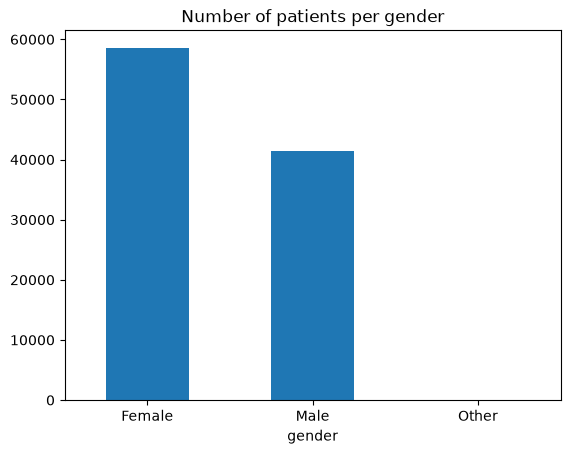

In [21]:
# Number of patients per gender
fig, ax = plt.subplots()
df_final["gender"].value_counts().plot.bar(
    ax=ax, title="Number of patients per gender", rot=0
)
fig.savefig(OUTPUT_DIR / "patients_per_gender.png", bbox_inches="tight")

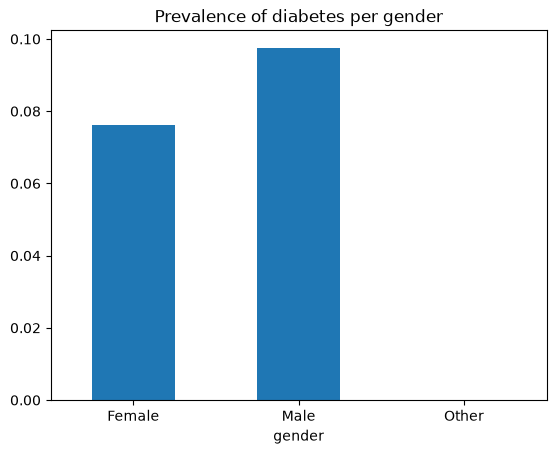

In [22]:
# Prevalence of diabetes per gender
fig, ax = plt.subplots()
prevalence_by_gender.plot.bar(ax=ax, title="Prevalence of diabetes per gender", rot=0)
fig.savefig(OUTPUT_DIR / "prevalence_per_gender.png", bbox_inches="tight")

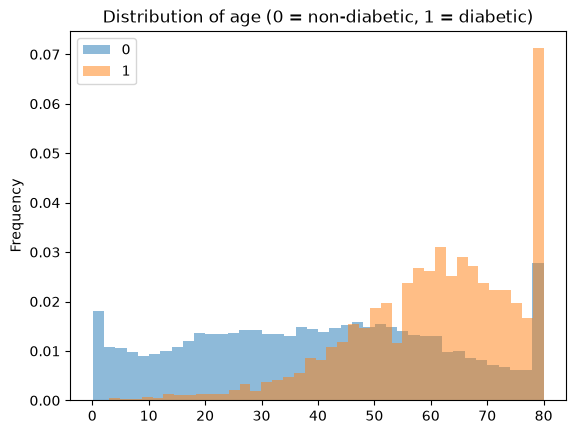

In [23]:
# Distribution of age: diabetic vs non-diabetic
fig, ax = plt.subplots()
df_final.groupby("diabetes")["age"].plot.hist(
    ax=ax, bins=40, alpha=0.5, density=True, legend=True
)
ax.set_title("Distribution of age (0 = non-diabetic, 1 = diabetic)")
fig.savefig(OUTPUT_DIR / "age_distribution.png", bbox_inches="tight")

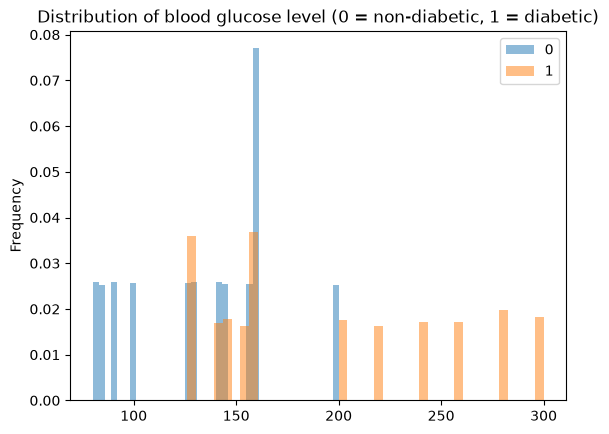

In [24]:
# Distribution of blood glucose: diabetic vs non-diabetic
fig, ax = plt.subplots()
df_final.groupby("diabetes")["blood_glucose_level"].plot.hist(
    ax=ax, bins=40, alpha=0.5, density=True, legend=True
)
ax.set_title("Distribution of blood glucose level (0 = non-diabetic, 1 = diabetic)")
fig.savefig(OUTPUT_DIR / "blood_glucose_distribution.png", bbox_inches="tight")

## Objective 4: Export the analysis

In [25]:
# Store the answers in a dictionary, then a DataFrame
dict_analysis = {
    "How many lines are in diabetes_part1.csv": len(part1),
    "How many lines are in diabetes_part2.csv": len(part2),
    "How many lines are in gender_mapping.csv": len(gender_mapping),
    "How many lines are exact duplicates": nb_duplicates,
    "How many patients were screened": nb_patients,
    "How many patients are diabetic": nb_diabetic,
    "What is the prevalence of diabetes": prevalence,
    "What is the prevalence of diabetes for women": prevalence_women,
    "What is the prevalence of diabetes for men": prevalence_men,
    "What is the average age of diabetic patients": age_diabetic,
    "What is the average age of non-diabetic patients": age_non_diabetic,
    "What is the prevalence of diabetes for patients with BMI >= 30": prevalence_obese,
    "What is the prevalence of diabetes for patients with BMI < 30": prevalence_not_obese,
    "What is the average HbA1c_level of diabetic patients": markers_by_diabetes.loc[
        1, "HbA1c_level"
    ],
    "What is the average HbA1c_level of non-diabetic patients": markers_by_diabetes.loc[
        0, "HbA1c_level"
    ],
    "What is the average blood_glucose_level of diabetic patients": markers_by_diabetes.loc[
        1, "blood_glucose_level"
    ],
    "What is the average blood_glucose_level of non-diabetic patients": markers_by_diabetes.loc[
        0, "blood_glucose_level"
    ],
    "How many times higher is the prevalence with hypertension": ratio_hypertension,
    "Which smoking_history category has the highest prevalence": top_smoking_category,
}
df_analysis = pd.DataFrame(list(dict_analysis.items()), columns=["Question", "Answer"])
df_analysis

,Question,Answer
0,How many lines are in diabetes_part1.csv,50000
1,How many lines are in diabetes_part2.csv,50000
2,How many lines are in gender_mapping.csv,3
3,How many lines are exact duplicates,3854
4,How many patients were screened,100000
5,How many patients are diabetic,8500
6,What is the prevalence of diabetes,0.085
7,What is the prevalence of diabetes for women,0.076189
8,What is the prevalence of diabetes for men,0.09749
9,What is the average age of diabetic patients,60.946588


In [26]:
# Export the tables and the graphs into one Excel file, one sheet each
graphs = [
    "patients_per_gender",
    "prevalence_per_gender",
    "age_distribution",
    "blood_glucose_distribution",
]

with pd.ExcelWriter(OUTPUT_DIR / "diabetes_analysis.xlsx") as writer:
    df_shapes.to_excel(writer, sheet_name="technical_q1_shapes", index=False)
    df_describe.to_excel(writer, sheet_name="technical_q5_describe")
    df_analysis.to_excel(writer, sheet_name="business_questions", index=False)

    sheet = writer.book.create_sheet("graphs")
    for i, name in enumerate(graphs):
        sheet.add_image(Image(OUTPUT_DIR / f"{name}.png"), f"A{1 + 25 * i}")

print(f"Analysis exported to {OUTPUT_DIR}")

Analysis exported to /Users/do/code/python_programming/course06/do_course06/data/output_v1
